# 1. Load the Dataset

In [1]:
import pandas as pd

df = pd.read_csv('processed_job_data.csv')
df.head()

,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,"['python', 'r']",['tableau'],['machine learning']
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...","['python', 'r']",[],['machine learning']
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,['python'],[],['machine learning']
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,"['python', 'r']",[],[]
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",['python'],[],['machine learning']


## 1.1 Restoring Extracted Columns as Python Lists

In [2]:
import ast 

df['extracted_skills'] = df['extracted_skills'].apply(ast.literal_eval)
df['extracted_tools'] = df['extracted_tools'].apply(ast.literal_eval)
df['extracted_technologies'] = df['extracted_technologies'].apply(ast.literal_eval)

In [3]:
type(df['extracted_skills'][0])

list

## 3.0 Preparing NLP Features for Machine Learning

In [4]:
df.explode('extracted_skills')['extracted_skills'].unique()

<StringArray>
['python', 'r', 'sql', nan]
Length: 4, dtype: str

In [5]:
ML_Skills = df.explode('extracted_skills')['extracted_skills'].value_counts().to_frame().reset_index()
ML_Skills = ML_Skills.rename(columns={
    'extracted_skills' : 'Skills'
})
ML_Skills

,Skills,count
0,python,36
1,sql,28
2,r,12


In [6]:
ML_Skills[ML_Skills['count'] >= 5]

,Skills,count
0,python,36
1,sql,28
2,r,12


## 3.1 Encoding NLP Skill Features into Machine Learning Variables

In [7]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb_skills = MultiLabelBinarizer()

skills_matrix = mlb_skills.fit_transform(df['extracted_skills'])
mlb_skills.classes_

print(skills_matrix)
print(mlb_skills.classes_)

[[1 1 0]
 [1 1 0]
 [1 0 0]
 [1 1 0]
 [1 0 0]
 [1 1 1]
 [1 0 0]
 [1 1 1]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 0]
 [1 0 1]
 [0 0 0]
 [0 0 0]
 [1 0 1]
 [1 1 1]
 [0 0 0]
 [1 1 1]
 [0 0 0]
 [1 0 1]
 [1 0 0]
 [1 0 0]
 [1 0 1]
 [0 0 0]
 [0 0 1]
 [0 0 0]
 [1 0 1]
 [1 1 1]
 [0 0 0]
 [1 0 1]
 [0 1 0]
 [1 1 1]
 [0 0 0]
 [1 0 1]
 [0 0 0]
 [0 0 1]
 [1 0 1]
 [1 0 1]
 [1 1 0]
 [1 1 1]
 [1 0 1]
 [0 0 1]
 [1 0 1]
 [1 0 1]
 [0 0 1]
 [0 0 1]
 [0 0 0]
 [0 0 0]
 [0 0 0]]
['python' 'r' 'sql']


In [8]:
skills_encoded_df = pd.DataFrame(
    data= skills_matrix,
    columns= mlb_skills.classes_
)
skills_encoded_df.head(5)

,python,r,sql
0,1,1,0
1,1,1,0
2,1,0,0
3,1,1,0
4,1,0,0


## 3.2 Integrating Encoded Skill Features into the Main Dataset

In [9]:
# Combine encoded skill features with the original dataset
ml_ready_df = pd.concat([df, skills_encoded_df], axis=1)

print(ml_ready_df.shape)
ml_ready_df.head()

(54, 16)


,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies,python,r,sql
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,"[python, r]",[tableau],[machine learning],1,1,0
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...","[python, r]",[],[machine learning],1,1,0
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,[python],[],[machine learning],1,0,0
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,"[python, r]",[],[],1,1,0
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",[python],[],[machine learning],1,0,0


## 3.3 Defining Features and Target for Machine Learning

In [10]:
# Define ML features and target variable
X = ml_ready_df[mlb_skills.classes_]
y = ml_ready_df['standardized_job_title']

In [11]:
print(X.head())
print(y.head())

   python  r  sql
0       1  1    0
1       1  1    0
2       1  0    0
3       1  1    0
4       1  0    0
0    data scientist
1    data scientist
2    data scientist
3    data scientist
4    data scientist
Name: standardized_job_title, dtype: str


## 3.4 Splitting Data into Training and Testing Sets

In [12]:
from sklearn.model_selection import train_test_split

#split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(43, 3) (43,)
(11, 3) (11,)


## 3.5 Training the First Machine Learning Model

In [14]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## 3.6 Making Predictions and Evaluating Model Performance

In [15]:
y_pred = model.predict(X_test)
y_pred

array(['data scientist', 'data analyst', 'data scientist',
       'data scientist', 'data scientist', 'data scientist',
       'data analyst', 'data analyst', 'data scientist', 'data scientist',
       'data scientist'], dtype=object)

In [16]:
y_test.values

<StringArray>
['data scientist',   'data analyst',   'data analyst', 'data scientist',
   'data analyst', 'data scientist', 'data scientist',   'data analyst',
 'data scientist',   'data analyst', 'data scientist']
Length: 11, dtype: str

In [17]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.64


## 3.7 Inspecting Model Predictions

In [18]:
# Compare actual and predicted job roles
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
comparison_df

,Actual,Predicted
19,data scientist,data scientist
49,data analyst,data analyst
48,data analyst,data scientist
12,data scientist,data scientist
44,data analyst,data scientist
5,data scientist,data scientist
17,data scientist,data analyst
52,data analyst,data analyst
3,data scientist,data scientist
32,data analyst,data scientist


## 3.8 Understanding Model Performance Beyond Accuracy

In [19]:
# Check target class distribution
ml_ready_df['standardized_job_title'].value_counts()

standardized_job_title
data scientist    28
data analyst      26
Name: count, dtype: int64

In [20]:
from sklearn.metrics import classification_report
report = classification_report(y_test, y_pred, output_dict=True)
print(report)

{'data analyst': {'precision': 0.6666666666666666, 'recall': 0.4, 'f1-score': 0.5, 'support': 5.0}, 'data scientist': {'precision': 0.625, 'recall': 0.8333333333333334, 'f1-score': 0.7142857142857143, 'support': 6.0}, 'accuracy': 0.6363636363636364, 'macro avg': {'precision': 0.6458333333333333, 'recall': 0.6166666666666667, 'f1-score': 0.6071428571428572, 'support': 11.0}, 'weighted avg': {'precision': 0.6439393939393939, 'recall': 0.6363636363636364, 'f1-score': 0.6168831168831169, 'support': 11.0}}


## 3.9 Understanding Confusion Matrix

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(model.classes_)
print(cm) #[ correct , wrong ]
          #[ wrong   , correct ]

['data analyst' 'data scientist']
[[2 3]
 [1 5]]


In [22]:
plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

NameError: name 'plt' is not defined

## Observation

- `2` job postings were correctly classified as **Data Analyst**, representing **True Negatives (TN)** because the actual and predicted class were both non-data scientist roles.
- `5` job postings were correctly classified as **Data Scientist**, representing **True Positives (TP)** because the actual and predicted class matched the positive target class.
- `3` actual **Data Analyst** roles were incorrectly predicted as **Data Scientist**, representing **False Positives (FP)** where the model incorrectly favored the positive class.
- `1` actual **Data Scientist** role was incorrectly predicted as **Data Analyst**, representing a **False Negative (FN)** where the model failed to identify the positive class.
- The confusion matrix suggests the model performs better at identifying **Data Scientist** roles than **Data Analyst** roles, likely due to overlapping skill patterns between the two job categories.

## 3.10 Testing the Model on New Custom Data

## Observation

- The trained Logistic Regression model successfully predicted a custom unseen skill profile as **Data Scientist**, demonstrating the model’s ability to generalize beyond the original dataset.
- The prediction workflow confirmed that new input data must follow the same feature structure used during training, including identical column names, order, and binary encoding format.
- The result suggests that strong association with **Python** and **R** skills influenced the prediction toward a **Data Scientist** role.
- This step simulates a real-world machine learning use case, where a trained model receives new user inputs and generates predictions without knowing the true outcome beforehand.

In [ ]:
new_profile = pd.DataFrame({
    'python': [1],
    'r': [1],
    'sql': [0]
})  
new_profile

,python,r,sql
0,1,1,0


In [ ]:
## Predict job role for a new custom skill profile
model.predict(new_profile) 

array(['data scientist'], dtype=object)

## 3.11 Understanding Feature Importance in Logistic Regression

## Observation

- **Python** has the strongest positive influence toward **Data Scientist** predictions, indicating it is the most distinguishing skill in the model.
- **SQL** shows a negative influence, suggesting stronger association with **Data Analyst** roles.
- **R** has minimal impact on prediction decisions, indicating weak separation power between the two job roles in this dataset.
- The coefficient analysis improves model interpretability by explaining how individual skills influence classification outcomes.

In [ ]:
print(model.classes_)
print(model.coef_)
print(X.columns)
#positive coefficient → pushes prediction toward second class
#negative coefficient → pushes prediction toward first class

['data analyst' 'data scientist']
[[ 1.65085576  0.12672816 -1.01645494]]
Index(['python', 'r', 'sql'], dtype='str')


## 3.12 Visualizing Logistic Regression Feature Importance

## Observation

- **Python** has the strongest influence in pushing predictions toward the **Data Scientist** class, making it the most important feature in the model.
- **R** has a small positive coefficient, indicating a weak influence toward **Data Scientist** predictions.
- **SQL** has a negative coefficient, meaning it pushes predictions toward the **Data Analyst** class.
- The coefficient values suggest that **Python** is the strongest differentiating skill, while **R** contributes only minimally to role separation in this dataset.

In [ ]:
# Create feature importance DataFrame from logistic regression coefficients
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})
feature_importance_df

,Feature,Coefficient
0,python,1.650856
1,r,0.126728
2,sql,-1.016455


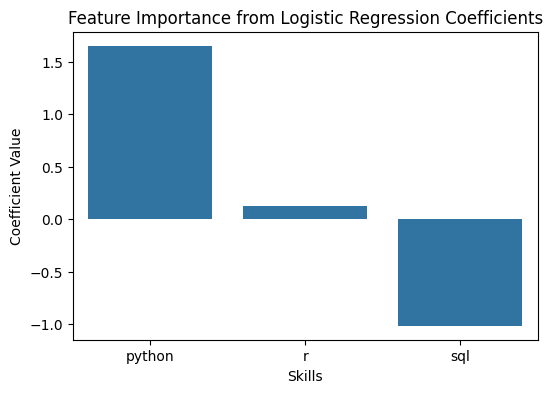

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(data = feature_importance_df,
            x='Feature',
            y='Coefficient')

plt.xlabel('Skills')
plt.ylabel('Coefficient Value')
plt.title('Feature Importance from Logistic Regression Coefficients')
plt.show()

## 3.13 Improving the Model with More NLP Features

## Observation

- The improved feature set was successfully split into training and testing subsets using the same reproducible configuration.
- The training and testing data now contain **8 encoded features**, reflecting the integration of **skills**, **tools**, and **technologies**.
- The target variable remained unchanged, while the feature space expanded to provide richer predictive information.
- Repeating the train-test split after feature engineering is necessary to ensure consistency between the updated feature matrix and model training process.

In [ ]:
mlb_tools = MultiLabelBinarizer()
tools_matrix = mlb_tools.fit_transform(df['extracted_tools'])


tools_encoded_df = pd.DataFrame(
    data= tools_matrix, 
    columns= mlb_tools.classes_
)
tools_encoded_df.head()

,powerbi,tableau
0,0,1
1,0,0
2,0,0
3,0,0
4,0,0


In [ ]:
mlb_technology = MultiLabelBinarizer()
technology_matrix = mlb_technology.fit_transform(df['extracted_technologies'])

technology_encoded_df = pd.DataFrame(
    data = technology_matrix,
    columns = mlb_technology.classes_
)
technology_encoded_df.head()


,deep learning,machine learning,nlp
0,0,1,0
1,0,1,0
2,0,1,0
3,0,0,0
4,0,1,0


In [ ]:
ml_ready_df_v2 = pd.concat([ml_ready_df, tools_encoded_df, technology_encoded_df], axis=1)
ml_ready_df_v2.head()

,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,...,extracted_tools,extracted_technologies,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,...,[tableau],[machine learning],1,1,0,0,1,0,1,0
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...",...,[],[machine learning],1,1,0,0,0,0,1,0
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,...,[],[machine learning],1,0,0,0,0,0,1,0
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,...,[],[],1,1,0,0,0,0,0,0
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",...,[],[machine learning],1,0,0,0,0,0,1,0


In [ ]:
print(ml_ready_df.shape)
print(ml_ready_df_v2.shape)

(54, 16)
(54, 21)


In [ ]:
all_features_encoded = (list(mlb_skills.classes_) +
                        list(mlb_tools.classes_) +
                        list(mlb_technology.classes_))

X = ml_ready_df_v2[all_features_encoded]
X.head()

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,1,0,0,1,0,1,0
1,1,1,0,0,0,0,1,0
2,1,0,0,0,0,0,1,0
3,1,1,0,0,0,0,0,0
4,1,0,0,0,0,0,1,0


In [ ]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(43, 8) (43,)
(11, 8) (11,)


## 3.14 Retraining the Model with Enhanced Features

## Observation

- The enhanced model achieved a more balanced classification performance across both job roles.
- From **5 actual Data Analyst** records, only **1 prediction was incorrect**, showing substantial improvement compared to the baseline model.
- From **6 actual Data Scientist** records, only **1 prediction was incorrect**, maintaining strong predictive performance.
- The confusion matrix indicates that misclassification errors decreased significantly after adding **tools** and **technologies** as features.
- The classification report shows balanced **precision**, **recall**, and **F1-score** across both classes, suggesting the model no longer strongly favors one role over the other.
- Compared to the baseline model (**0.64** accuracy), the enhanced model (**0.82** accuracy) demonstrates that **feature engineering improved model quality more effectively than changing algorithms**.

In [ ]:
model_v2 = LogisticRegression()
model_v2.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
y_pred_v2 = model_v2.predict(X_test)
y_pred_v2

array(['data scientist', 'data analyst', 'data analyst', 'data scientist',
       'data analyst', 'data scientist', 'data scientist', 'data analyst',
       'data analyst', 'data scientist', 'data scientist'], dtype=object)

In [ ]:
accuracy_v2 = accuracy_score(y_test, y_pred_v2)
print(f'Accuracy with Skills, Tools, and Technologies: {accuracy_v2:.2f}')

Accuracy with Skills, Tools, and Technologies: 0.82


In [ ]:
confusion_matrix_v2 = confusion_matrix(y_test, y_pred_v2)
confusion_matrix_v2

array([[4, 1],
       [1, 5]])

In [ ]:
report_v2 = classification_report(y_test, y_pred_v2, output_dict=True)
print(report_v2)

{'data analyst': {'precision': 0.8, 'recall': 0.8, 'f1-score': 0.8, 'support': 5.0}, 'data scientist': {'precision': 0.8333333333333334, 'recall': 0.8333333333333334, 'f1-score': 0.8333333333333334, 'support': 6.0}, 'accuracy': 0.8181818181818182, 'macro avg': {'precision': 0.8166666666666667, 'recall': 0.8166666666666667, 'f1-score': 0.8166666666666667, 'support': 11.0}, 'weighted avg': {'precision': 0.8181818181818182, 'recall': 0.8181818181818182, 'f1-score': 0.8181818181818182, 'support': 11.0}}


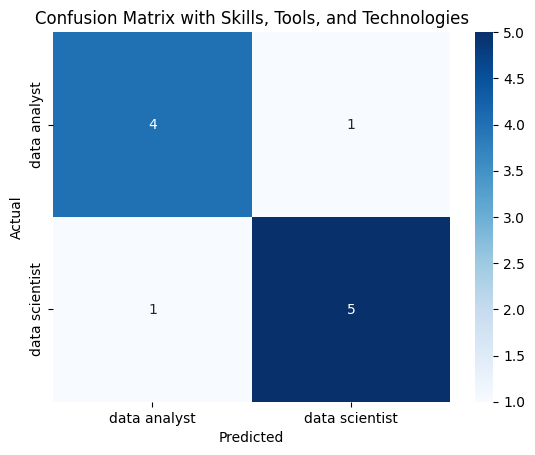

In [ ]:
plt.Figure(figsize=(6,4))

sns.heatmap(confusion_matrix_v2, annot=True, fmt='d', cmap='Blues', xticklabels=model_v2.classes_, yticklabels=model_v2.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with Skills, Tools, and Technologies')
plt.show()

## 3.15 Comparing Model Versions

## Observation

- The comparison table clearly shows that **Model V2** outperformed **Model V1** after adding **tools** and **technologies** as features.
- Overall accuracy improved from **0.64** to **0.82**, indicating stronger classification performance.
- **Data Analyst recall** increased significantly from **0.40** to **0.80**, showing that the enhanced model became much better at correctly identifying analyst roles.
- **Data Scientist recall** remained stable at **0.83**, meaning the improvement in analyst prediction did not negatively impact scientist classification.
- The comparison confirms that **feature engineering improved model balance and predictive quality without changing the underlying algorithm**.

In [ ]:
report['data analyst']

{'precision': 0.6666666666666666,
 'recall': 0.4,
 'f1-score': 0.5,
 'support': 5.0}

In [ ]:
pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline Model': [accuracy, report['data analyst']['precision'], report['data analyst']['recall'], report['data analyst']['f1-score']],
    'Enhanced Model': [accuracy_v2, report_v2['data analyst']['precision'], report_v2['data analyst']['recall'], report_v2['data analyst']['f1-score']]
})

,Metric,Baseline Model,Enhanced Model
0,Accuracy,0.636364,0.818182
1,Precision,0.666667,0.800000
2,Recall,0.400000,0.800000
3,F1-Score,0.500000,0.800000


In [ ]:
model_comparison_df = pd.DataFrame({
    'Metric': ['Accuracy',
               'Data Analyst Recall ', 
               'Data Scientist Recall',],
    'Baseline Model': [accuracy,
                report['data analyst']['recall'],
                report['data scientist']['recall']],
    'Enhanced Model': [accuracy_v2, 
                report_v2['data analyst']['recall'],
                report_v2['data scientist']['recall']]
})

model_comparison_df.round(2)

,Metric,Baseline Model,Enhanced Model
0,Accuracy,0.64,0.82
1,Data Analyst Recall,0.40,0.80
2,Data Scientist Recall,0.83,0.83


## 3.16 Visualizing Model Comparison

## Observation

- The model comparison visualization was improved by moving the legend outside the chart, preventing overlap with plotted data.
- Adding metric values directly on the bars increased readability and made performance differences easier to interpret.
- The enhanced visualization clearly communicates the improvement from the **Baseline Model** to the **Enhanced Model**, especially for **Data Analyst recall** and overall **accuracy**.
- Presentation-ready visualizations improve stakeholder understanding by making model performance easier to interpret than raw numbers alone.

In [ ]:
model_comparison_long = model_comparison_df.melt(
    id_vars='Metric',
    var_name='Model',
    value_name='Score'
)
model_comparison_long

,Metric,Model,Score
0,Accuracy,Baseline Model,0.636364
1,Data Analyst Recall,Baseline Model,0.400000
2,Data Scientist Recall,Baseline Model,0.833333
3,Accuracy,Enhanced Model,0.818182
4,Data Analyst Recall,Enhanced Model,0.800000
5,Data Scientist Recall,Enhanced Model,0.833333


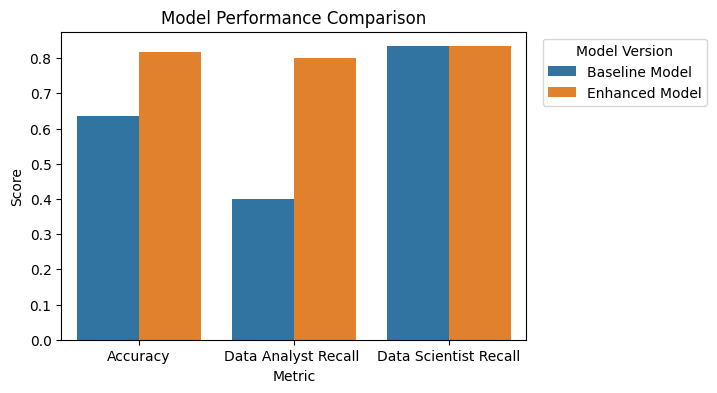

In [ ]:
plt.figure(figsize=(6,4))

sns.barplot(data = model_comparison_long,
            x='Metric',
            y='Score',
            hue='Model')

plt.xlabel('Metric')
plt.ylabel('Score')
    
plt.legend(
    title='Model Version',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.title('Model Performance Comparison')
plt.show()

## 3.17 Testing the Enhanced Model on New Custom Profiles

## Observation

- The enhanced Logistic Regression model was successfully tested on multiple unseen custom profiles, simulating real-world prediction scenarios.
- A **Data Scientist-like profile** containing features such as **Python**, **Machine Learning**, **Deep Learning**, and **NLP** was correctly classified as **Data Scientist**.
- A **Data Analyst-like profile** emphasizing **SQL**, **Power BI**, and **Tableau** was correctly classified as **Data Analyst**.
- The results indicate that the enhanced model learned meaningful relationships between skills, tools, and technologies, improving prediction logic beyond the training dataset.
- This step validates the model’s ability to generalize and make consistent predictions on new user-defined inputs.

In [ ]:
X.columns

Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')

In [ ]:
new_profile_v2 = pd.DataFrame({
    'python': [1],
    'r': [0],
    'sql': [1],
    'powerbi': [0],
    'tableau': [0],
    'deep learning': [1],
    'machine learning': [1],
    'nlp': [1]
})
new_profile_v2

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,0,1,0,0,1,1,1


In [ ]:
model_v2.predict(new_profile_v2)

array(['data scientist'], dtype=object)

In [ ]:
new_profile_v3 = pd.DataFrame({
    'python': [1],
    'r': [0],
    'sql': [1],
    'powerbi': [1],
    'tableau': [1],
    'deep learning': [0],
    'machine learning': [0],
    'nlp': [0]
})
new_profile_v3

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,0,1,1,1,0,0,0


In [ ]:
model_v2.predict(new_profile_v3)

array(['data analyst'], dtype=object)

## 3.18 Understanding Feature Importance in the Enhanced Model

In [ ]:
print(X.columns)
print(model_v2.coef_)
print(model_v2.classes_)

Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')
[[ 0.98355619  0.24581729 -0.34018053 -0.3389344  -0.55780339  0.65506149
   2.19038482  0.66230248]]
['data analyst' 'data scientist']


In [ ]:
model_coefficients_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model_v2.coef_[0]
})
model_coefficients_df

,feature,coefficient
0,python,0.983556
1,r,0.245817
2,sql,-0.340181
3,powerbi,-0.338934
4,tableau,-0.557803
5,deep learning,0.655061
6,machine learning,2.190385
7,nlp,0.662302


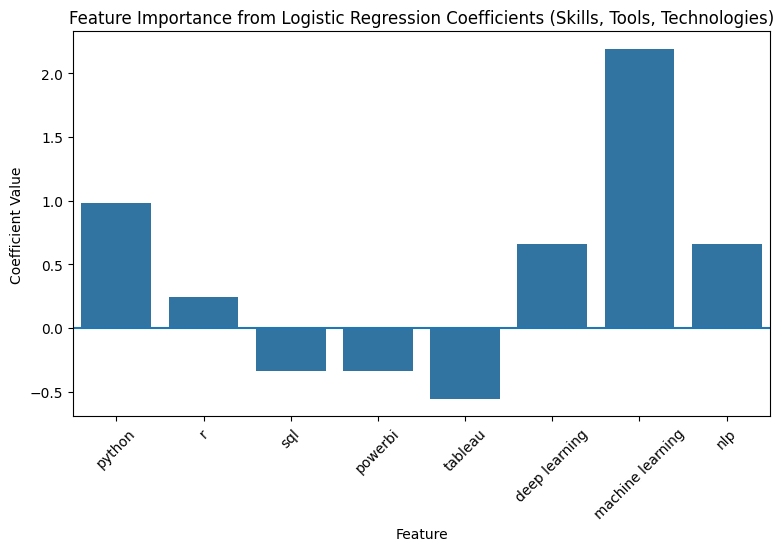

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(data = model_coefficients_df,
            x='feature',
            y='coefficient')

plt.axhline(y=0)

plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.title('Feature Importance from Logistic Regression Coefficients (Skills, Tools, Technologies)')
plt.xticks(rotation=45)
plt.show()

## 3.19 Comparing Feature Importance: Baseline vs Enhanced Model

## Observation

- The feature importance comparison visualization highlights how model reasoning evolved after feature engineering.
- In the **Baseline Model**, **Python** had the strongest positive influence toward **Data Scientist** predictions due to the limited feature set.
- In the **Enhanced Model**, **Machine Learning** became the strongest predictive feature, while **Tableau** emerged as a strong indicator of **Data Analyst** roles.
- The influence of **Python** decreased in the enhanced model because additional features such as **Deep Learning**, **Machine Learning**, and **NLP** provided stronger explanatory signals.
- Comparing feature importance across model versions demonstrates how richer features improved interpretability and role differentiation.

In [ ]:
baseline_coefficients_df = pd.DataFrame({
    'Feature': mlb_skills.classes_,
    'Coefficient': model.coef_[0],
    'Model': 'Baseline Model'
})

In [ ]:
enhanced_coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_v2.coef_[0],
    'Model': 'Enhanced Model'
})

In [ ]:
feature_importance_comparison_df = pd.concat(
    [baseline_coefficients_df,
     enhanced_coefficients_df],
    axis=0
)

feature_importance_comparison_df

,Feature,Coefficient,Model
0,python,1.650856,Baseline Model
1,r,0.126728,Baseline Model
2,sql,-1.016455,Baseline Model
0,python,0.983556,Enhanced Model
1,r,0.245817,Enhanced Model
2,sql,-0.340181,Enhanced Model
3,powerbi,-0.338934,Enhanced Model
4,tableau,-0.557803,Enhanced Model
5,deep learning,0.655061,Enhanced Model
6,machine learning,2.190385,Enhanced Model


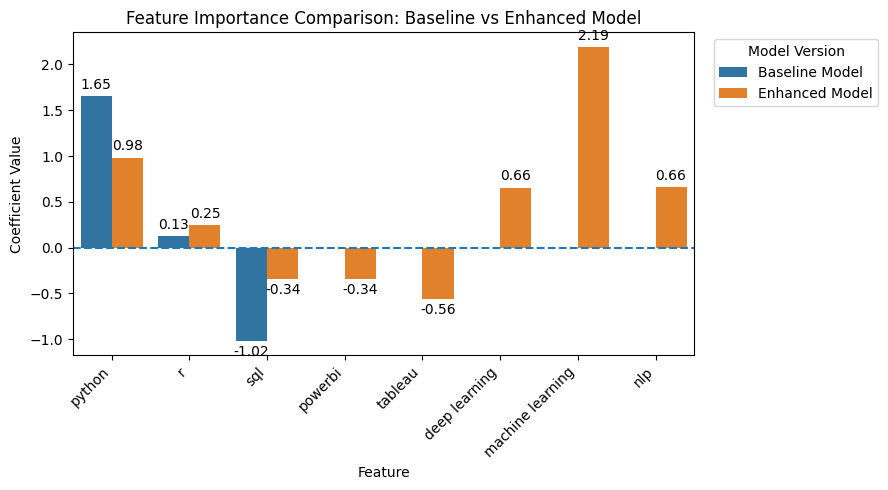

In [ ]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=feature_importance_comparison_df,
    x='Feature',
    y='Coefficient',
    hue='Model'
)

# Reference line for positive vs negative influence
plt.axhline(y=0, linestyle='--')

# Show values on bars
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.2f', padding=3)

plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.title('Feature Importance Comparison: Baseline vs Enhanced Model')

# Improve readability of feature names
plt.xticks(rotation=45, ha='right')

# Move legend outside chart
plt.legend(
    title='Model Version',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# Prevent clipping
plt.tight_layout()

plt.show()

## 3.20 Saving the Final Model

## Observation

- The final enhanced Logistic Regression model was successfully saved using `joblib`.
- The model was saved inside the project-level `models/` directory, keeping trained ML assets organized professionally.
- The path issue occurred because the notebook was running from the `notebooks/` folder, so `../models/` was needed to access the project root.
- Saving the trained model allows future predictions without retraining the model from scratch.

In [ ]:
import joblib
joblib.dump(model_v2,
             '../models/job_role_classifier_v2.pkl')


['../models/job_role_classifier_v2.pkl']

## 3.21 Loading the Saved Model

## Observation

- The saved model was successfully loaded back into the notebook using `joblib.load()`.
- After deleting the original `model_v2` from memory, the loaded model was still able to generate predictions correctly.
- The loaded model predicted the custom Data Scientist-like profile as **Data Scientist**, confirming that the saved model file works as expected.
- This validates the full model persistence workflow: **train → save → load → predict**.

In [ ]:
#del model_v2
loaded_model = joblib.load(
    '../models/job_role_classifier_v2.pkl'
)

loaded_model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [ ]:
loaded_model.predict(new_profile_v2)

array(['data scientist'], dtype=object)

## 3.22 Saving Required ML Assets for Future Predictions

## Observation

- The feature column schema was successfully saved and reloaded using `joblib`.
- Validation confirmed that the loaded feature columns exactly match `X.columns`, preserving the correct feature order used during training.
- Saving feature columns alongside the trained model ensures consistent preprocessing and prevents feature mismatch during future predictions.
- This step strengthens model reproducibility by allowing predictions to be generated with the same input structure used during training.

In [ ]:
# Save feature order for future predictions
joblib.dump(
    X.columns,
    '../models/model_feature_columns.pkl'
)

['../models/model_feature_columns.pkl']

In [ ]:
loaded_features_columns = joblib.load('../models/model_feature_columns.pkl')
print(loaded_features_columns)
print(X.columns)

Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')
Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')


## 3.23 Simulating a Real-World Prediction Workflow

## Observation

- A real-world prediction workflow was successfully simulated using the saved model and feature schema.
- Raw user input was automatically converted into a model-ready feature structure without manually encoding each feature.
- Dictionary comprehension and automatic feature mapping ensured consistency with the original training feature order.
- The loaded model successfully predicted the new profile as **Data Scientist**, validating the end-to-end prediction pipeline.
- This step demonstrates a production-style workflow where new inputs can be transformed and predicted automatically.

In [ ]:
feature_dict = {
    feature: 0
    for feature in loaded_features_columns
}
feature_dict

{'python': 0,
 'r': 0,
 'sql': 0,
 'powerbi': 0,
 'tableau': 0,
 'deep learning': 0,
 'machine learning': 0,
 'nlp': 0}

In [ ]:
new_skills = [
    'python',
    'sql',
    'machine learning'
]

for skill in new_skills:
    feature_dict[skill] = 1

feature_dict


{'python': 1,
 'r': 0,
 'sql': 1,
 'powerbi': 0,
 'tableau': 0,
 'deep learning': 0,
 'machine learning': 1,
 'nlp': 0}

In [ ]:
new_profile_df = pd.DataFrame([feature_dict])
new_profile_df

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,0,1,0,0,0,1,0


In [ ]:
loaded_model.predict(new_profile_df)

array(['data scientist'], dtype=object)

## 3.24 Creating a Reusable Prediction Function

## Observation

- A reusable prediction function was successfully created to automate the full prediction workflow.
- The function automatically converts raw user skills into the correct model-ready feature structure, removing the need for manual encoding.
- Input normalization using `.lower()` improved robustness by allowing predictions from uppercase, lowercase, or mixed-case user inputs.
- Unknown or unsupported skills are safely ignored, preventing prediction failures and improving usability.
- This step transforms the project from a manual ML experiment into a reusable and production-style prediction pipeline.

In [ ]:
def predict_job_role_for_profile(skills):
    feature_dict = {
    feature: 0
    for feature in loaded_features_columns
}
    for skill in skills:
        skill= skill.lower()
        if skill in feature_dict:
            feature_dict[skill] = 1
    new_profile_df = pd.DataFrame([feature_dict])
    return loaded_model.predict(new_profile_df)[0]

In [ ]:
predict_job_role_for_profile([
    'Python',
    'SQL',
    'Machine Learning'
])

'data scientist'

In [ ]:
predict_job_role_for_profile([
    'SQL',
    'PowerBI',
    'TABLEAU'
])

'data analyst'

## 3.25 Final ML Pipeline Summary

## Final ML Pipeline Summary

In this machine learning phase, a complete end-to-end job role classification pipeline was developed to distinguish between **Data Analyst** and **Data Scientist** roles based on extracted job posting features.

The workflow started by transforming extracted **skills**, **tools**, and **technologies** into machine-readable numerical features using **MultiLabelBinarizer**, enabling machine learning models to process textual information.

A **baseline Logistic Regression model** was first trained using only skills-based features. After evaluating its performance, weaknesses were identified, particularly in predicting **Data Analyst** roles. To improve performance, **feature engineering** was applied by incorporating additional **tools** and **technologies** into the feature set.

The enhanced model achieved significantly better performance, improving accuracy from **0.64** to **0.82**, while also producing more balanced classification results across both job roles. Feature importance analysis showed that **Machine Learning** became the strongest indicator of **Data Scientist** roles, while **Tableau** strongly influenced **Data Analyst** predictions.

To simulate real-world machine learning practices, the final model was saved using **joblib**, reloaded successfully, and tested on unseen custom profiles. Finally, a reusable prediction function was developed to automatically transform user-provided skills into the required model format and generate predictions, making the workflow more scalable and production-ready.